<a href="https://colab.research.google.com/github/Maryvictor/precos_imoveis_ml/blob/main/Projeto_Regressao_Alura.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 1 - Modelo de Regressão

## 1.1 Apresentação

## 1.2 Carregando os dados

[JSON Viewer](http://jsonviewer.stack.hu)

[Pandas: read_json](https://pandas.pydata.org/docs/reference/api/pandas.read_json.html?highlight=read_json#pandas.read_json)


In [482]:
import pandas as pd
import numpy as np


In [483]:
dados = pd.read_json('imoveis.json')

### Explorar as informações

In [484]:
dados

,ident,listing
0,"{'customerID': '775564-BOJSMVON', 'source': 'W...","{'types': {'unit': 'Outros', 'usage': 'Residen..."
1,"{'customerID': '660895-AUENKNYY', 'source': 'W...","{'types': {'unit': 'Apartamento', 'usage': 'Re..."
2,"{'customerID': '751522-JESYFEQL', 'source': 'W...","{'types': {'unit': 'Outros', 'usage': 'Residen..."
3,"{'customerID': '714052-GAAEWYKS', 'source': 'W...","{'types': {'unit': 'Outros', 'usage': 'Comerci..."
4,"{'customerID': '568886-ZIBFOMCC', 'source': 'W...","{'types': {'unit': 'Apartamento', 'usage': 'Re..."
...,...,...
73610,"{'customerID': '134148-MJIBCMDQ', 'source': 'W...","{'types': {'unit': 'Casa', 'usage': 'Residenci..."
73611,"{'customerID': '541465-QBQVXXXZ', 'source': 'W...","{'types': {'unit': 'Casa', 'usage': 'Residenci..."
73612,"{'customerID': '800542-BZREFTQS', 'source': 'W...","{'types': {'unit': 'Apartamento', 'usage': 'Re..."
73613,"{'customerID': '939419-ECGUNTIH', 'source': 'W...","{'types': {'unit': 'Casa', 'usage': 'Residenci..."


In [485]:
dados.ident[0]

{'customerID': '775564-BOJSMVON', 'source': 'Website'}

In [486]:
dados.listing[0]

{'types': {'unit': 'Outros', 'usage': 'Residencial'},
 'address': {'city': 'Rio de Janeiro',
  'location': {'lon': -43.413557, 'lat': -22.909429},
  'zone': 'Zona Oeste',
  'neighborhood': 'Taquara'},
 'prices': {'price': '45000', 'tax': {'iptu': '0', 'condo': '150'}},
 'features': {'bedrooms': 0,
  'bathrooms': 0,
  'suites': 0,
  'parkingSpaces': 1,
  'usableAreas': '62',
  'totalAreas': '62',
  'floors': 0,
  'unitsOnTheFloor': 0,
  'unitFloor': 0}}

## 1.3 Tratamento de dados inicial

### Normalização

In [487]:
dados_parte_1 = pd.json_normalize(dados.ident)
dados_parte_2 = pd.json_normalize(dados.listing)

In [488]:
dados_parte_1


,customerID,source
0,775564-BOJSMVON,Website
1,660895-AUENKNYY,Website
2,751522-JESYFEQL,Website
3,714052-GAAEWYKS,Website
4,568886-ZIBFOMCC,Website
...,...,...
73610,134148-MJIBCMDQ,Website
73611,541465-QBQVXXXZ,Website
73612,800542-BZREFTQS,Website
73613,939419-ECGUNTIH,Website


### Junção dos dataframes

In [489]:
dados_parte_2

,types.unit,types.usage,address.city,address.location.lon,address.location.lat,address.zone,address.neighborhood,prices.price,prices.tax.iptu,prices.tax.condo,features.bedrooms,features.bathrooms,features.suites,features.parkingSpaces,features.usableAreas,features.totalAreas,features.floors,features.unitsOnTheFloor,features.unitFloor
0,Outros,Residencial,Rio de Janeiro,-43.413557,-22.909429,Zona Oeste,Taquara,45000,0,150,0,0,0,1,62,62,0,0,0
1,Apartamento,Residencial,Rio de Janeiro,-43.509141,-22.869698,Zona Oeste,Santíssimo,45000,0,120,2,1,0,1,44,0,0,0,0
2,Outros,Residencial,Rio de Janeiro,-43.646786,-22.986927,Zona Oeste,Pedra de Guaratiba,50000,0,100,0,0,0,0,132,132,0,0,0
3,Outros,Comercial,Rio de Janeiro,-43.330818,-22.881977,Zona Norte,Cascadura,45000,346,468,0,1,0,0,32,32,0,0,3
4,Apartamento,Residencial,Rio de Janeiro,-43.480742,-23.027653,Zona Oeste,Recreio dos Bandeirantes,50000,120,400,3,2,1,1,60,0,3,4,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73610,Casa,Residencial,Rio de Janeiro,-43.388906,-23.003960,Zona Oeste,Barra da Tijuca,10000000,2900,2350,5,10,1,4,1024,1024,0,0,0
73611,Casa,Residencial,Rio de Janeiro,-43.395032,-23.000902,Zona Oeste,Barra da Tijuca,10000000,15000,3000,5,7,5,6,750,1250,0,0,0
73612,Apartamento,Residencial,Rio de Janeiro,-43.189682,-22.987018,Zona Sul,Copacabana,10000000,None,None,4,5,4,3,328,328,0,0,0
73613,Casa,Residencial,Rio de Janeiro,-43.351836,-23.005037,Zona Oeste,Barra da Tijuca,10000000,35000,2400,5,10,5,4,1024,1024,0,0,3


In [490]:
dados_imoveis = pd.concat([dados_parte_1, dados_parte_2], axis=1)

In [491]:
dados_imoveis

,customerID,source,types.unit,types.usage,address.city,address.location.lon,address.location.lat,address.zone,address.neighborhood,prices.price,...,prices.tax.condo,features.bedrooms,features.bathrooms,features.suites,features.parkingSpaces,features.usableAreas,features.totalAreas,features.floors,features.unitsOnTheFloor,features.unitFloor
0,775564-BOJSMVON,Website,Outros,Residencial,Rio de Janeiro,-43.413557,-22.909429,Zona Oeste,Taquara,45000,...,150,0,0,0,1,62,62,0,0,0
1,660895-AUENKNYY,Website,Apartamento,Residencial,Rio de Janeiro,-43.509141,-22.869698,Zona Oeste,Santíssimo,45000,...,120,2,1,0,1,44,0,0,0,0
2,751522-JESYFEQL,Website,Outros,Residencial,Rio de Janeiro,-43.646786,-22.986927,Zona Oeste,Pedra de Guaratiba,50000,...,100,0,0,0,0,132,132,0,0,0
3,714052-GAAEWYKS,Website,Outros,Comercial,Rio de Janeiro,-43.330818,-22.881977,Zona Norte,Cascadura,45000,...,468,0,1,0,0,32,32,0,0,3
4,568886-ZIBFOMCC,Website,Apartamento,Residencial,Rio de Janeiro,-43.480742,-23.027653,Zona Oeste,Recreio dos Bandeirantes,50000,...,400,3,2,1,1,60,0,3,4,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73610,134148-MJIBCMDQ,Website,Casa,Residencial,Rio de Janeiro,-43.388906,-23.003960,Zona Oeste,Barra da Tijuca,10000000,...,2350,5,10,1,4,1024,1024,0,0,0
73611,541465-QBQVXXXZ,Website,Casa,Residencial,Rio de Janeiro,-43.395032,-23.000902,Zona Oeste,Barra da Tijuca,10000000,...,3000,5,7,5,6,750,1250,0,0,0
73612,800542-BZREFTQS,Website,Apartamento,Residencial,Rio de Janeiro,-43.189682,-22.987018,Zona Sul,Copacabana,10000000,...,None,4,5,4,3,328,328,0,0,0
73613,939419-ECGUNTIH,Website,Casa,Residencial,Rio de Janeiro,-43.351836,-23.005037,Zona Oeste,Barra da Tijuca,10000000,...,2400,5,10,5,4,1024,1024,0,0,3


In [492]:
dados_imoveis.shape

(73615, 21)

In [493]:
dados_imoveis.columns

Index(['customerID', 'source', 'types.unit', 'types.usage', 'address.city',
       'address.location.lon', 'address.location.lat', 'address.zone',
       'address.neighborhood', 'prices.price', 'prices.tax.iptu',
       'prices.tax.condo', 'features.bedrooms', 'features.bathrooms',
       'features.suites', 'features.parkingSpaces', 'features.usableAreas',
       'features.totalAreas', 'features.floors', 'features.unitsOnTheFloor',
       'features.unitFloor'],
      dtype='object')

In [494]:
dados_imoveis.rename(columns={
    'customerID':                  'id_cliente',
    'source':                      'fonte',
    'types.unit':                  'tipo_unidade',
    'types.usage':                 'tipo_uso',
    'address.city':                'cidade',
    'address.location.lon':        'longitude',
    'address.location.lat':        'latitude',
    'address.zone':                'zona',
    'address.neighborhood':        'bairro',
    'prices.price':                'preco_venda',
    'prices.tax.iptu':             'taxa_iptu',
    'prices.tax.condo':            'taxa_condominio',
    'features.bedrooms':           'quartos',
    'features.bathrooms':          'banheiros',
    'features.suites':             'suites',
    'features.parkingSpaces':      'vagas_garagem',
    'features.usableAreas':        'area_util',
    'features.totalAreas':         'area_total',
    'features.floors':             'total_andares',
    'features.unitsOnTheFloor':    'unidades_por_andar',
    'features.unitFloor':          'andar',
}, inplace=True)

In [495]:
dados_imoveis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73615 entries, 0 to 73614
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_cliente          73615 non-null  object 
 1   fonte               73615 non-null  object 
 2   tipo_unidade        73615 non-null  object 
 3   tipo_uso            73615 non-null  object 
 4   cidade              73615 non-null  object 
 5   longitude           73468 non-null  float64
 6   latitude            73468 non-null  float64
 7   zona                73615 non-null  object 
 8   bairro              73615 non-null  object 
 9   preco_venda         73615 non-null  object 
 10  taxa_iptu           64499 non-null  object 
 11  taxa_condominio     67111 non-null  object 
 12  quartos             73615 non-null  int64  
 13  banheiros           73615 non-null  int64  
 14  suites              73615 non-null  int64  
 15  vagas_garagem       73615 non-null  int64  
 16  area

In [496]:
for colunas in dados_imoveis.columns:
  print('==============='*30)
  print(dados_imoveis[colunas].value_counts())

id_cliente
775564-BOJSMVON    1
660895-AUENKNYY    1
751522-JESYFEQL    1
714052-GAAEWYKS    1
568886-ZIBFOMCC    1
                  ..
134148-MJIBCMDQ    1
541465-QBQVXXXZ    1
800542-BZREFTQS    1
939419-ECGUNTIH    1
610503-VULDJJZZ    1
Name: count, Length: 73615, dtype: int64
fonte
Website    73615
Name: count, dtype: int64
tipo_unidade
Apartamento    59106
Casa            9389
Outros          5120
Name: count, dtype: int64
tipo_uso
Residencial    69596
Comercial       4019
Name: count, dtype: int64
cidade
Rio de Janeiro        73607
Queimados                 3
São Gonçalo               2
Cachoeirinha              1
São João de Meriti        1
Armação dos Búzios        1
Name: count, dtype: int64
longitude
-43.365895    399
-43.462590    278
-43.333066    236
-43.383834    232
-43.516473    218
             ... 
-43.233688      1
-43.175559      1
-43.315563      1
-43.244513      1
-43.181262      1
Name: count, Length: 25753, dtype: int64
latitude
-23.000371    399
-23.017479  

## 1.4 Limpeza

### Filtro

In [497]:
filtro = (dados_imoveis['tipo_uso'] == 'Residencial') & (dados_imoveis['cidade'] == 'Rio de Janeiro')

In [498]:
dados_imoveis = dados_imoveis[filtro]

dados_imoveis.head()



,id_cliente,fonte,tipo_unidade,tipo_uso,cidade,longitude,latitude,zona,bairro,preco_venda,...,taxa_condominio,quartos,banheiros,suites,vagas_garagem,area_util,area_total,total_andares,unidades_por_andar,andar
0,775564-BOJSMVON,Website,Outros,Residencial,Rio de Janeiro,-43.413557,-22.909429,Zona Oeste,Taquara,45000,...,150,0,0,0,1,62,62,0,0,0
1,660895-AUENKNYY,Website,Apartamento,Residencial,Rio de Janeiro,-43.509141,-22.869698,Zona Oeste,Santíssimo,45000,...,120,2,1,0,1,44,0,0,0,0
2,751522-JESYFEQL,Website,Outros,Residencial,Rio de Janeiro,-43.646786,-22.986927,Zona Oeste,Pedra de Guaratiba,50000,...,100,0,0,0,0,132,132,0,0,0
4,568886-ZIBFOMCC,Website,Apartamento,Residencial,Rio de Janeiro,-43.480742,-23.027653,Zona Oeste,Recreio dos Bandeirantes,50000,...,400,3,2,1,1,60,0,3,4,2
5,526755-OBLTYTEN,Website,Outros,Residencial,Rio de Janeiro,-43.571183,-22.966059,Zona Oeste,Guaratiba,50000,...,0,0,0,0,0,200,200,0,0,0


### Tipos de variáveis

In [499]:
dados_imoveis.info()

<class 'pandas.core.frame.DataFrame'>
Index: 69588 entries, 0 to 73614
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_cliente          69588 non-null  object 
 1   fonte               69588 non-null  object 
 2   tipo_unidade        69588 non-null  object 
 3   tipo_uso            69588 non-null  object 
 4   cidade              69588 non-null  object 
 5   longitude           69449 non-null  float64
 6   latitude            69449 non-null  float64
 7   zona                69588 non-null  object 
 8   bairro              69588 non-null  object 
 9   preco_venda         69588 non-null  object 
 10  taxa_iptu           60863 non-null  object 
 11  taxa_condominio     63527 non-null  object 
 12  quartos             69588 non-null  int64  
 13  banheiros           69588 non-null  int64  
 14  suites              69588 non-null  int64  
 15  vagas_garagem       69588 non-null  int64  
 16  area_util

Verificando a saída do `.info`

> 69588 entries, 0 to 73614

 percebemos que temos que resentar o index, para que as infos fiquem ordenadas corretamente.


In [500]:
dados_imoveis.reset_index(drop=True, inplace=True)

In [501]:
dados_imoveis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69588 entries, 0 to 69587
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_cliente          69588 non-null  object 
 1   fonte               69588 non-null  object 
 2   tipo_unidade        69588 non-null  object 
 3   tipo_uso            69588 non-null  object 
 4   cidade              69588 non-null  object 
 5   longitude           69449 non-null  float64
 6   latitude            69449 non-null  float64
 7   zona                69588 non-null  object 
 8   bairro              69588 non-null  object 
 9   preco_venda         69588 non-null  object 
 10  taxa_iptu           60863 non-null  object 
 11  taxa_condominio     63527 non-null  object 
 12  quartos             69588 non-null  int64  
 13  banheiros           69588 non-null  int64  
 14  suites              69588 non-null  int64  
 15  vagas_garagem       69588 non-null  int64  
 16  area

Agora está correto.

In [502]:
dados_imoveis['area_util'].apply(lambda x: float(x).is_integer()).all()

np.True_

In [503]:
dados_imoveis['area_total'].apply(lambda x: float(x).is_integer()).all()

np.True_

In [504]:
dados_imoveis['area_util'] = dados_imoveis['area_util'].astype('int64')

/tmp/ipykernel_10975/1237034046.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_imoveis['area_util'] = dados_imoveis['area_util'].astype('int64')


In [505]:
dados_imoveis['area_total'] = dados_imoveis['area_total'].astype('int64')

/tmp/ipykernel_10975/918472035.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_imoveis['area_total'] = dados_imoveis['area_total'].astype('int64')


In [506]:
dados_imoveis.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69588 entries, 0 to 69587
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_cliente          69588 non-null  object 
 1   fonte               69588 non-null  object 
 2   tipo_unidade        69588 non-null  object 
 3   tipo_uso            69588 non-null  object 
 4   cidade              69588 non-null  object 
 5   longitude           69449 non-null  float64
 6   latitude            69449 non-null  float64
 7   zona                69588 non-null  object 
 8   bairro              69588 non-null  object 
 9   preco_venda         69588 non-null  object 
 10  taxa_iptu           60863 non-null  object 
 11  taxa_condominio     63527 non-null  object 
 12  quartos             69588 non-null  int64  
 13  banheiros           69588 non-null  int64  
 14  suites              69588 non-null  int64  
 15  vagas_garagem       69588 non-null  int64  
 16  area

In [507]:
dados_imoveis['preco_venda'].apply(lambda x: float(x).is_integer()).all()

np.True_

In [508]:
dados_imoveis['preco_venda'] = dados_imoveis['preco_venda'].astype('int64')

/tmp/ipykernel_10975/1901636929.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_imoveis['preco_venda'] = dados_imoveis['preco_venda'].astype('int64')


In [509]:
dados_imoveis['preco_venda']

,preco_venda
0,45000
1,45000
2,50000
3,50000
4,50000
...,...
69583,10000000
69584,10000000
69585,10000000
69586,10000000


In [510]:
dados_imoveis['taxa_iptu'].dropna().apply(lambda x: float(x).is_integer()).all()

np.True_

In [511]:
dados_imoveis['taxa_iptu'] = dados_imoveis['taxa_iptu'].astype('Int64')

/tmp/ipykernel_10975/2197062087.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_imoveis['taxa_iptu'] = dados_imoveis['taxa_iptu'].astype('Int64')


In [512]:
dados_imoveis['taxa_condominio'].dropna().apply(lambda x: float(x).is_integer()).all()

np.True_

In [513]:
dados_imoveis['taxa_condominio'] = dados_imoveis['taxa_condominio'].astype('Int64')

/tmp/ipykernel_10975/4117807046.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_imoveis['taxa_condominio'] = dados_imoveis['taxa_condominio'].astype('Int64')


In [514]:
dados_imoveis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69588 entries, 0 to 69587
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_cliente          69588 non-null  object 
 1   fonte               69588 non-null  object 
 2   tipo_unidade        69588 non-null  object 
 3   tipo_uso            69588 non-null  object 
 4   cidade              69588 non-null  object 
 5   longitude           69449 non-null  float64
 6   latitude            69449 non-null  float64
 7   zona                69588 non-null  object 
 8   bairro              69588 non-null  object 
 9   preco_venda         69588 non-null  int64  
 10  taxa_iptu           60863 non-null  Int64  
 11  taxa_condominio     63527 non-null  Int64  
 12  quartos             69588 non-null  int64  
 13  banheiros           69588 non-null  int64  
 14  suites              69588 non-null  int64  
 15  vagas_garagem       69588 non-null  int64  
 16  area

## 1.5 - Tratamento de dados final

### Lidando com dados nulos

#### Dados nulos zone

In [515]:
dados_imoveis['zona'].str.strip().eq('').sum()

np.int64(149)

In [516]:
dados_imoveis['zona'].unique()

array(['Zona Oeste', 'Zona Norte', 'Zona Central', 'Zona Sul', ''],
      dtype=object)

In [517]:
dados_imoveis['zona'] = dados_imoveis['zona'].replace('', np.nan)

/tmp/ipykernel_10975/4286640884.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_imoveis['zona'] = dados_imoveis['zona'].replace('', np.nan)


In [518]:
dados_imoveis['zona'].unique()

array(['Zona Oeste', 'Zona Norte', 'Zona Central', 'Zona Sul', nan],
      dtype=object)

In [519]:
dici = dados_imoveis[~dados_imoveis['zona'].isna()]

In [520]:
print(
    dados_imoveis.loc[
        dados_imoveis['zona'].isna(),
        'bairro'
    ].drop_duplicates().to_string(index=False)
)

                  Centro
            Campo Grande
      Pedra de Guaratiba
                  Grajaú
    São Francisco Xavier
             Vila Isabel
                  Tijuca
            Santa Teresa
                 Catumbi
            Rio Comprido
                 Andaraí
                Maracanã
               Riachuelo
           Vargem Grande
       Praça da Bandeira
                Flamengo
           São Cristóvão
Recreio dos Bandeirantes
       Alto da Boa Vista
             Jacarepaguá
                 Ipanema
                  Leblon
                   Lagoa
              Copacabana


In [521]:
# Bairros que possuem zona nula
bairros_nulos = dados_imoveis.loc[
    dados_imoveis['zona'].isna(), 'bairro'
].unique()

# Consultar as zonas já preenchidas desses bairros
consulta = (
    dados_imoveis.loc[
        dados_imoveis['bairro'].isin(bairros_nulos)
        & dados_imoveis['zona'].notna(),
        ['bairro', 'zona']
    ]
    .value_counts()
    .reset_index(name='quantidade')
    .sort_values(['bairro', 'quantidade'],
                 ascending=[True, False])
)

print(consulta.to_string(index=False))

                  bairro         zona  quantidade
       Alto da Boa Vista   Zona Norte          44
                 Andaraí   Zona Norte         413
            Campo Grande   Zona Oeste        1238
                 Catumbi Zona Central          16
                 Catumbi     Zona Sul           5
                  Centro Zona Central         626
                  Centro     Zona Sul          27
              Copacabana     Zona Sul        6153
                Flamengo     Zona Sul        1191
                  Grajaú   Zona Norte         420
                 Ipanema     Zona Sul        1848
             Jacarepaguá   Zona Oeste        4014
             Jacarepaguá     Zona Sul           2
             Jacarepaguá   Zona Norte           1
                   Lagoa     Zona Sul         939
                  Leblon     Zona Sul        1952
                Maracanã   Zona Norte         639
      Pedra de Guaratiba   Zona Oeste          74
       Praça da Bandeira   Zona Norte         178


In [522]:
dados_imoveis.groupby('bairro')['zona'].nunique().sort_values(ascending=False)

,zona
bairro,
Bonsucesso,3
Praça da Bandeira,3
Jacarepaguá,3
Tijuca,3
Rio Comprido,3
...,...
Vila da Penha,1
Vista Alegre,1
Zumbi,1


In [523]:
# Quantidade de zonas distintas por bairro
contagem_zonas = dados_imoveis.groupby('bairro')['zona'].nunique()

# Selecionar bairros com mais de uma zona
bairros_conflitantes = contagem_zonas[contagem_zonas > 1]

print(bairros_conflitantes.to_string())

bairro
Barra da Tijuca             2
Bonsucesso                  3
Campinho                    2
Catumbi                     2
Centro                      2
Cidade Nova                 2
Cidade Universitária        2
Cosmos                      2
Engenho Novo                2
Engenho de Dentro           2
Estácio                     3
Glória                      2
Guadalupe                   2
Inhoaíba                    2
Jacarepaguá                 3
Joá                         2
Mangueira                   2
Oswaldo Cruz                2
Padre Miguel                2
Parada de Lucas             2
Portuguesa                  2
Praça Seca                  2
Praça da Bandeira           3
Ramos                       2
Realengo                    2
Recreio dos Bandeirantes    2
Rio Comprido                3
Santa Teresa                2
Sepetiba                    2
São Conrado                 2
São Cristóvão               2
Tanque                      2
Tijuca                      3
Vil

In [524]:
consulta_conflitos = (
    dados_imoveis[
        dados_imoveis['bairro'].isin(bairros_conflitantes.index)
    ]
    .groupby(['bairro', 'zona'])
    .size()
    .reset_index(name='quantidade')
    .sort_values(['bairro', 'quantidade'], ascending=[True, False])
)

print(consulta_conflitos.to_string(index=False))

                  bairro         zona  quantidade
         Barra da Tijuca   Zona Oeste       11127
         Barra da Tijuca   Zona Norte           2
              Bonsucesso   Zona Norte          95
              Bonsucesso     Zona Sul           6
              Bonsucesso   Zona Oeste           1
                Campinho   Zona Norte         100
                Campinho   Zona Oeste          11
                 Catumbi Zona Central          16
                 Catumbi     Zona Sul           5
                  Centro Zona Central         626
                  Centro     Zona Sul          27
             Cidade Nova Zona Central          14
             Cidade Nova   Zona Norte           1
    Cidade Universitária   Zona Oeste           2
    Cidade Universitária   Zona Norte           1
                  Cosmos   Zona Oeste          44
                  Cosmos     Zona Sul           2
            Engenho Novo   Zona Norte         275
            Engenho Novo     Zona Sul          11


In [525]:
from padronizar_zonas_imoveis_rio import padronizar_zonas

dados_imoveis, auditoria = padronizar_zonas(dados_imoveis)

Registros: 69,588 | Bairros da base: 152
Nulos antes: 149 | Nulos depois: 0
Preenchidos nesta execução: 149 | Corrigidos nesta execução: 1137
Todos os nomes de bairros desta base tiveram correspondência.
Aviso: "Área Rural de Rio de Janeiro" foi atribuída à Zona Oeste por hipótese DIDÁTICA.


In [526]:
print(dados_imoveis['zona'].value_counts(dropna=False))
print(dados_imoveis['zona'].isna().sum())

zona
Zona Oeste      35564
Zona Sul        17808
Zona Norte      14275
Zona Central     1941
Name: count, dtype: int64
0


#### Dados nulos prices

In [527]:
dados_imoveis['taxa_iptu'].isnull().sum()

np.int64(8725)

In [528]:
dados_imoveis['taxa_condominio'].isnull().sum()

np.int64(6061)

In [529]:
dados_imoveis['taxa_iptu'].fillna(0, inplace=True)
dados_imoveis['taxa_condominio'].fillna(0, inplace=True)

/tmp/ipykernel_10975/2344317649.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dados_imoveis['taxa_iptu'].fillna(0, inplace=True)
/tmp/ipykernel_10975/2344317649.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', 

In [530]:
dados_imoveis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69588 entries, 0 to 69587
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 69588 non-null  object 
 1   fonte                      69588 non-null  object 
 2   tipo_unidade               69588 non-null  object 
 3   tipo_uso                   69588 non-null  object 
 4   cidade                     69588 non-null  object 
 5   longitude                  69449 non-null  float64
 6   latitude                   69449 non-null  float64
 7   zona                       69588 non-null  object 
 8   bairro                     69588 non-null  object 
 9   preco_venda                69588 non-null  int64  
 10  taxa_iptu                  69588 non-null  Int64  
 11  taxa_condominio            69588 non-null  Int64  
 12  quartos                    69588 non-null  int64  
 13  banheiros                  69588 non-null  int

### Alterar o nome das colunas e seleção de variáveis

In [531]:
dados_imoveis.drop(['id_cliente', 'fonte', 'tipo_uso', 'cidade', 'longitude', 'latitude', 'zona_original', 'zona_antes_desta_execucao', 'criterio_zona', 'zona_5_regioes_referencia', 'zona_corrigida'], axis = 1, inplace=True)

In [532]:
dados_imoveis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69588 entries, 0 to 69587
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   tipo_unidade        69588 non-null  object
 1   zona                69588 non-null  object
 2   bairro              69588 non-null  object
 3   preco_venda         69588 non-null  int64 
 4   taxa_iptu           69588 non-null  Int64 
 5   taxa_condominio     69588 non-null  Int64 
 6   quartos             69588 non-null  int64 
 7   banheiros           69588 non-null  int64 
 8   suites              69588 non-null  int64 
 9   vagas_garagem       69588 non-null  int64 
 10  area_util           69588 non-null  int64 
 11  area_total          69588 non-null  int64 
 12  total_andares       69588 non-null  int64 
 13  unidades_por_andar  69588 non-null  int64 
 14  andar               69588 non-null  int64 
dtypes: Int64(2), int64(10), object(3)
memory usage: 8.1+ MB


In [533]:
dados_imoveis

,tipo_unidade,zona,bairro,preco_venda,taxa_iptu,taxa_condominio,quartos,banheiros,suites,vagas_garagem,area_util,area_total,total_andares,unidades_por_andar,andar
0,Outros,Zona Oeste,Taquara,45000,0,150,0,0,0,1,62,62,0,0,0
1,Apartamento,Zona Oeste,Santíssimo,45000,0,120,2,1,0,1,44,0,0,0,0
2,Outros,Zona Oeste,Pedra de Guaratiba,50000,0,100,0,0,0,0,132,132,0,0,0
3,Apartamento,Zona Oeste,Recreio dos Bandeirantes,50000,120,400,3,2,1,1,60,0,3,4,2
4,Outros,Zona Oeste,Guaratiba,50000,0,0,0,0,0,0,200,200,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69583,Casa,Zona Oeste,Barra da Tijuca,10000000,2900,2350,5,10,1,4,1024,1024,0,0,0
69584,Casa,Zona Oeste,Barra da Tijuca,10000000,15000,3000,5,7,5,6,750,1250,0,0,0
69585,Apartamento,Zona Sul,Copacabana,10000000,0,0,4,5,4,3,328,328,0,0,0
69586,Casa,Zona Oeste,Barra da Tijuca,10000000,35000,2400,5,10,5,4,1024,1024,0,0,3


# Aula 2 - Regressão linear

## 2.1 - Correlação

*   Correlação: grau da relação entre variáveis. Pode ser positiva ou negativa essa relação.

*   Multicolinearidade: relação perfeita ou exata entre variáveis.



**Dica de leitura:** [Estatística prática para cientistas de dados: 50 conceitos essenciais](https://www.amazon.com.br/Estat%C3%ADstica-Pr%C3%A1tica-Para-Cientistas-Dados/dp/855080603X/ref=sr_1_21?__mk_pt_BR=%C3%85M%C3%85%C5%BD%C3%95%C3%91&crid=1JJ44C5LJXLR3&keywords=data+science&qid=1657892785&sprefix=data+science%2Caps%2C201&sr=8-21)
e [Estatística: O que é, para que serve e como funciona](https://www.amazon.com.br/Estat%C3%ADstica-para-serve-como-funciona/dp/8537815128/ref=pd_sbs_sccl_3_1/137-9319794-7502061?pd_rd_w=EQoo7&content-id=amzn1.sym.d27ac626-cb3c-4c30-830f-0fd405f2510f&pf_rd_p=d27ac626-cb3c-4c30-830f-0fd405f2510f&pf_rd_r=E896BYW6W206YVVR3SHA&pd_rd_wg=3O0Cg&pd_rd_r=3e3910b0-5f34-4a57-87b2-1d918494d614&pd_rd_i=8537815128&psc=1) [(Naked Statistics: Stripping the Dread from the Data - versão em inglês)](https://www.amazon.com.br/Naked-Statistics-Stripping-Dread-Data/dp/039334777X/ref=sr_1_2?keywords=naked+statistics&qid=1657893464&sprefix=naked+st%2Caps%2C267&sr=8-2&ufe=app_do%3Aamzn1.fos.6a09f7ec-d911-4889-ad70-de8dd83c8a74)

In [534]:
correlacao = dados_imoveis.corr(numeric_only=True)


correlacao

,preco_venda,taxa_iptu,taxa_condominio,quartos,banheiros,suites,vagas_garagem,area_util,area_total,total_andares,unidades_por_andar,andar
preco_venda,1.000000,0.029751,0.047704,0.530474,0.571725,0.588738,0.423186,0.692502,-0.000619,-0.061910,-0.133700,-0.000143
taxa_iptu,0.029751,1.000000,0.226213,0.013625,0.015086,0.019101,0.009720,0.014654,-0.000164,0.006704,0.005044,0.001204
taxa_condominio,0.047704,0.226213,1.000000,0.018460,0.020009,0.023479,0.018010,0.019712,-0.000313,0.013821,-0.000528,0.003072
quartos,0.530474,0.013625,0.018460,1.000000,0.665958,0.600596,0.467391,0.563545,-0.000532,-0.082025,-0.130611,-0.007146
banheiros,0.571725,0.015086,0.020009,0.665958,1.000000,0.752495,0.487624,0.597793,0.000041,-0.044552,-0.107347,0.007599
suites,0.588738,0.019101,0.023479,0.600596,0.752495,1.000000,0.484850,0.577344,0.003971,-0.047576,-0.091408,0.005300
vagas_garagem,0.423186,0.009720,0.018010,0.467391,0.487624,0.484850,1.000000,0.483709,-0.000062,-0.048310,-0.074348,0.003788
area_util,0.692502,0.014654,0.019712,0.563545,0.597793,0.577344,0.483709,1.000000,-0.000214,-0.103729,-0.144041,-0.012715
area_total,-0.000619,-0.000164,-0.000313,-0.000532,0.000041,0.003971,-0.000062,-0.000214,1.000000,0.014677,0.003975,0.002329
total_andares,-0.061910,0.006704,0.013821,-0.082025,-0.044552,-0.047576,-0.048310,-0.103729,0.014677,1.000000,0.737802,0.121067


In [535]:
import matplotlib.pyplot as plt
import seaborn as sns

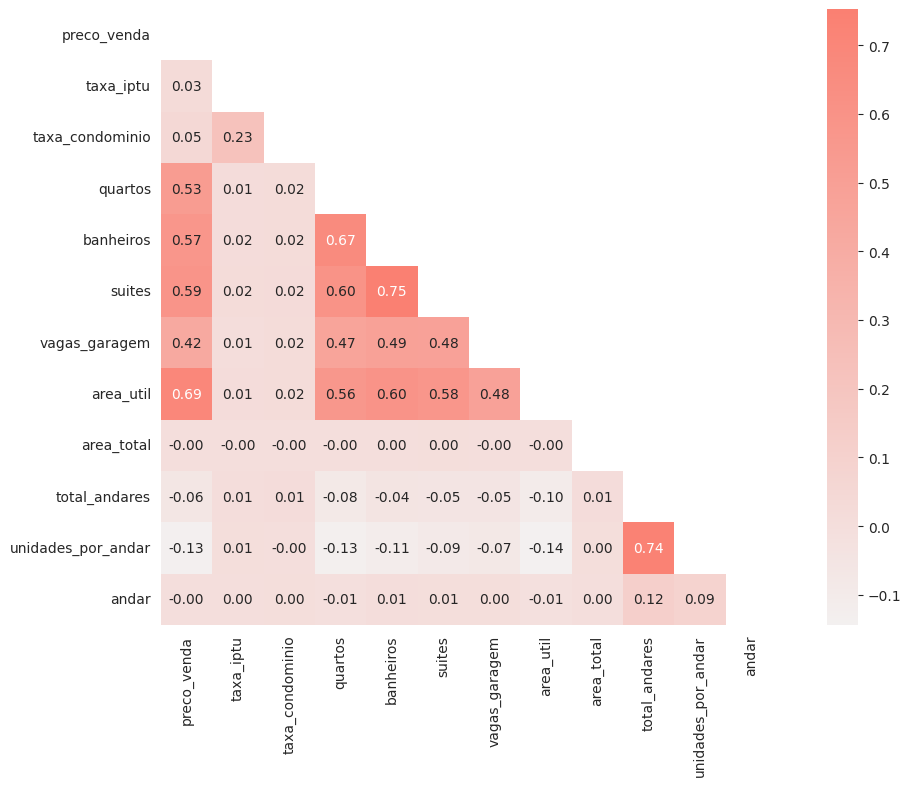

In [536]:
# Visualização das correlações
cores = sns.color_palette('light:salmon', as_cmap=True)

mask = np.zeros_like(correlacao)
mask[np.triu_indices_from(mask)] = True

with sns.axes_style("white"):
    f, ax = plt.subplots(figsize=(13, 8))
    ax = sns.heatmap(
        correlacao,
        cmap=cores,
        mask=mask,
        square=True,
        fmt='.2f',
        annot=True
    )

Para mais detalhes consultar [Documentação Seaborn](https://seaborn.pydata.org/generated/seaborn.heatmap.html)

In [537]:
dados_imoveis['area_total']

,area_total
0,62
1,0
2,132
3,0
4,200
...,...
69583,1024
69584,1250
69585,328
69586,1024


Análise da distribuição da variável resposta.

Text(0.5, 0, 'Preço')

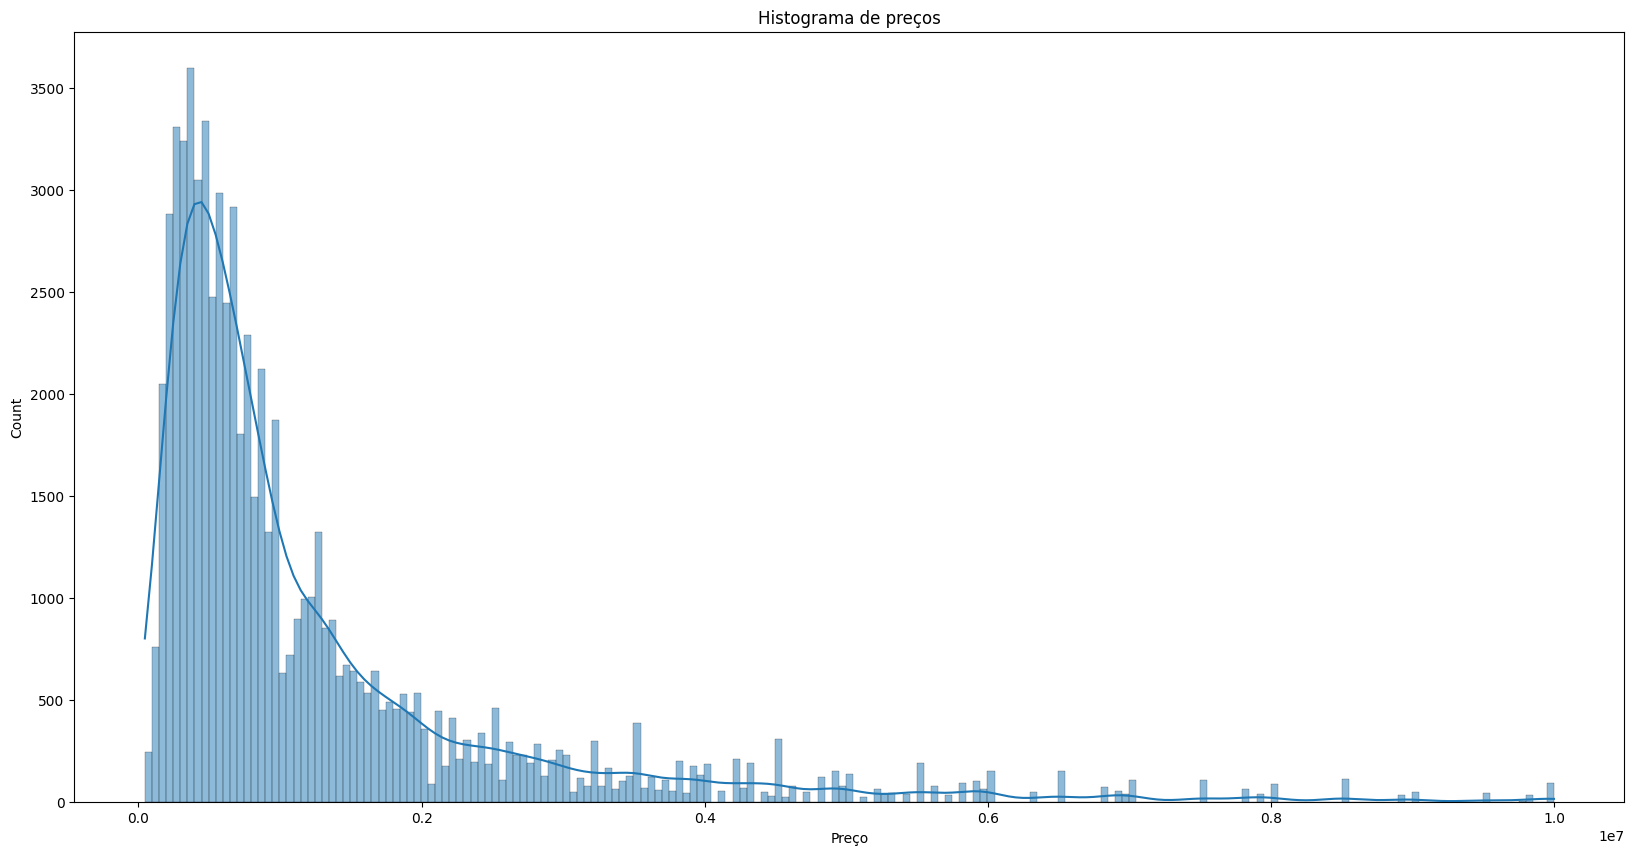

In [538]:
# Antes (distribuição: assimetria à direita)
ax = sns.histplot(data=dados_imoveis, x='preco_venda', kde=True)
ax.figure.set_size_inches(20, 10)
ax.set_title('Histograma de preços')
ax.set_xlabel('Preço')

### Transformação das variáveis

Estamos realizando uma transformação logarítmica das variáveis para obtermos uma distribuição simétrica (mais próxima da normal), para que possamos usar o modelo de regressão linear. A transformação realizada é:


$$log1p = log(1+x)$$


Lembrar de realizar a transformação inversa para obter o valor original:


$$expm1 = exp(x) - 1$$




* Para mais detalhes consultar as documentações [`log1p`](https://numpy.org/doc/stable/reference/generated/numpy.log1p.html), [`expm1`](https://numpy.org/doc/stable/reference/generated/numpy.expm1.html#numpy.expm1) e [`FunctionTransformer`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.FunctionTransformer.html#sklearn.preprocessing.FunctionTransformer)



In [539]:
from sklearn.preprocessing import FunctionTransformer

transformer = FunctionTransformer(np.log1p, validate=True)

dados_transformados = transformer.transform(
    dados_imoveis.select_dtypes(exclude=['object'])
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but FunctionTransformer was fitted without feature names
  warnings.warn(


In [540]:
colunas_dados_transformados = dados_imoveis.select_dtypes(exclude=['object']).columns

df_transformado = pd.concat([
    dados_imoveis.select_dtypes(include=['object']),
    pd.DataFrame(
        dados_transformados,
        columns=colunas_dados_transformados,
        index=dados_imoveis.index
    )
], axis=1)

df_transformado.head()

,tipo_unidade,zona,bairro,preco_venda,taxa_iptu,taxa_condominio,quartos,banheiros,suites,vagas_garagem,area_util,area_total,total_andares,unidades_por_andar,andar
0,Outros,Zona Oeste,Taquara,10.714440,0.000000,5.017280,0.000000,0.000000,0.000000,0.693147,4.143135,4.143135,0.000000,0.000000,0.000000
1,Apartamento,Zona Oeste,Santíssimo,10.714440,0.000000,4.795791,1.098612,0.693147,0.000000,0.693147,3.806662,0.000000,0.000000,0.000000,0.000000
2,Outros,Zona Oeste,Pedra de Guaratiba,10.819798,0.000000,4.615121,0.000000,0.000000,0.000000,0.000000,4.890349,4.890349,0.000000,0.000000,0.000000
3,Apartamento,Zona Oeste,Recreio dos Bandeirantes,10.819798,4.795791,5.993961,1.386294,1.098612,0.693147,0.693147,4.110874,0.000000,1.386294,1.609438,1.098612
4,Outros,Zona Oeste,Guaratiba,10.819798,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.303305,5.303305,0.000000,0.000000,0.000000


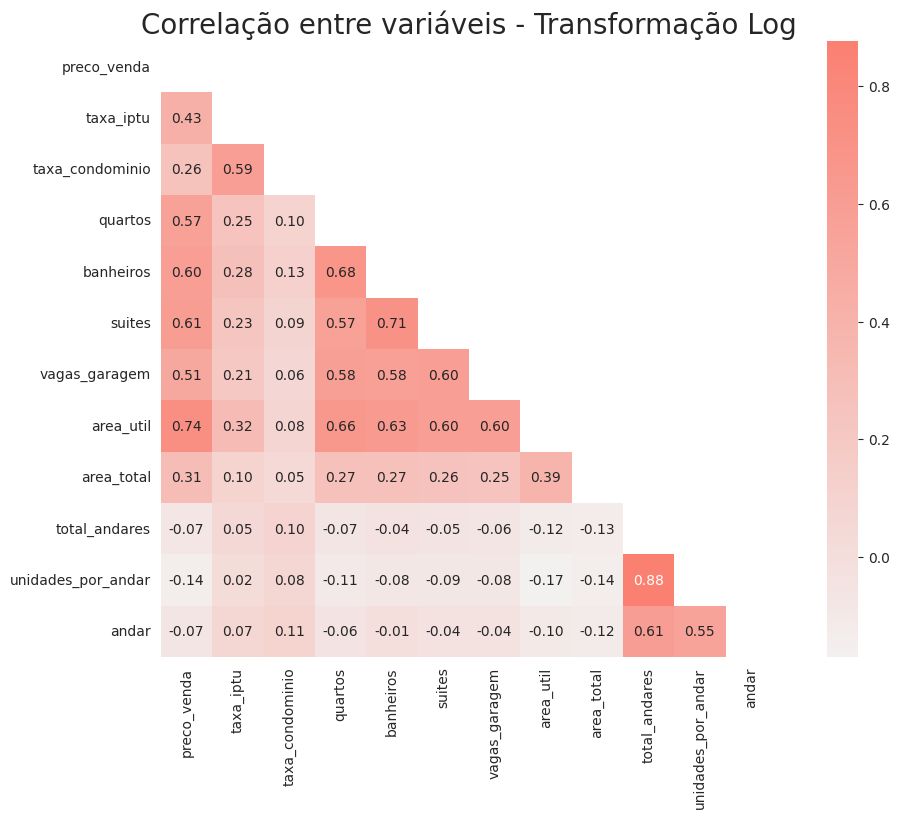

In [541]:
# Depois da transformação
correlacao_transformado = df_transformado.corr(numeric_only=True)

mask = np.zeros_like(correlacao_transformado)
mask[np.triu_indices_from(mask)] = True

with sns.axes_style("white"):
    f, ax = plt.subplots(figsize=(13, 8))
    ax = sns.heatmap(
        correlacao_transformado,
        cmap=cores,
        mask=mask,
        square=True,
        fmt='.2f',
        annot=True
    )
    ax.set_title(
        'Correlação entre variáveis - Transformação Log',
        fontsize=20
    )

Text(0.5, 0, 'Preço')

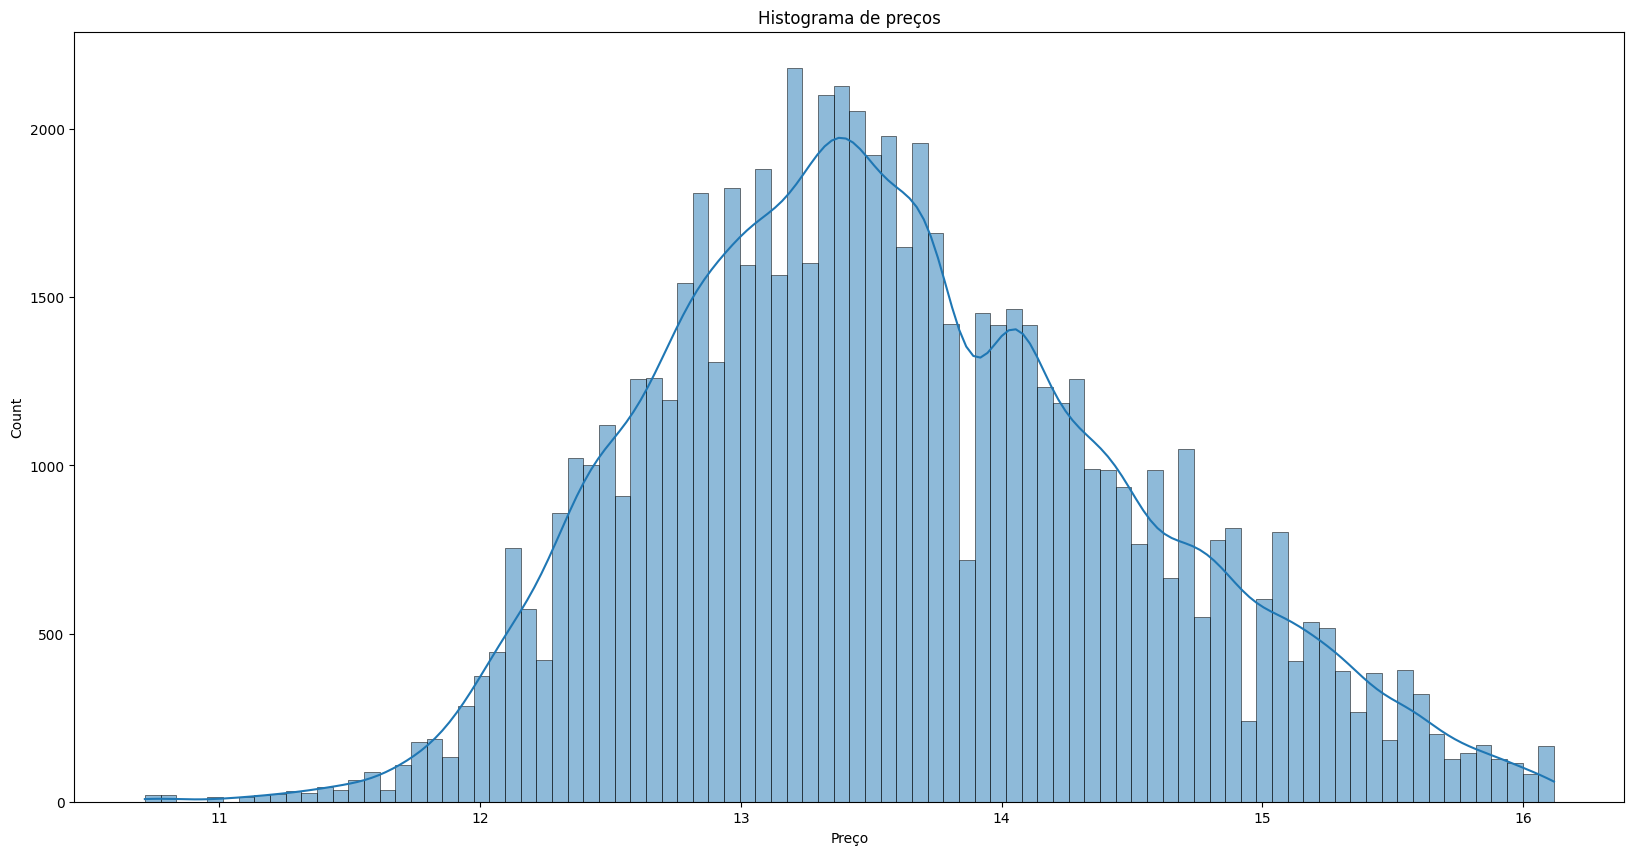

In [542]:
# Depois (distribuição simétrica)
ax = sns.histplot(data=df_transformado, x='preco_venda', kde=True)
ax.figure.set_size_inches(20, 10)
ax.set_title('Histograma de preços')
ax.set_xlabel('Preço')

### Dummies

In [543]:
variaveis_categoricas = df_transformado.select_dtypes(include=['object']).columns

In [544]:
variaveis_categoricas

Index(['tipo_unidade', 'zona', 'bairro'], dtype='object')

In [545]:
variaveis_categoricas = variaveis_categoricas.drop('bairro')

In [546]:
df_dummies = pd.get_dummies(
    df_transformado[variaveis_categoricas],
    dtype=int
)

df_dummies.head()

,tipo_unidade_Apartamento,tipo_unidade_Casa,tipo_unidade_Outros,zona_Zona Central,zona_Zona Norte,zona_Zona Oeste,zona_Zona Sul
0,0,0,1,0,0,1,0
1,1,0,0,0,0,1,0
2,0,0,1,0,0,1,0
3,1,0,0,0,0,1,0
4,0,0,1,0,0,1,0


In [547]:
dados_imoveis_dummies = pd.concat([
    df_transformado.drop(variaveis_categoricas, axis=1),
    df_dummies
], axis=1)

dados_imoveis_dummies.head()

,bairro,preco_venda,taxa_iptu,taxa_condominio,quartos,banheiros,suites,vagas_garagem,area_util,area_total,total_andares,unidades_por_andar,andar,tipo_unidade_Apartamento,tipo_unidade_Casa,tipo_unidade_Outros,zona_Zona Central,zona_Zona Norte,zona_Zona Oeste,zona_Zona Sul
0,Taquara,10.714440,0.000000,5.017280,0.000000,0.000000,0.000000,0.693147,4.143135,4.143135,0.000000,0.000000,0.000000,0,0,1,0,0,1,0
1,Santíssimo,10.714440,0.000000,4.795791,1.098612,0.693147,0.000000,0.693147,3.806662,0.000000,0.000000,0.000000,0.000000,1,0,0,0,0,1,0
2,Pedra de Guaratiba,10.819798,0.000000,4.615121,0.000000,0.000000,0.000000,0.000000,4.890349,4.890349,0.000000,0.000000,0.000000,0,0,1,0,0,1,0
3,Recreio dos Bandeirantes,10.819798,4.795791,5.993961,1.386294,1.098612,0.693147,0.693147,4.110874,0.000000,1.386294,1.609438,1.098612,1,0,0,0,0,1,0
4,Guaratiba,10.819798,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.303305,5.303305,0.000000,0.000000,0.000000,0,0,1,0,0,1,0


In [548]:
dados_imoveis_dummies.columns

Index(['bairro', 'preco_venda', 'taxa_iptu', 'taxa_condominio', 'quartos',
       'banheiros', 'suites', 'vagas_garagem', 'area_util', 'area_total',
       'total_andares', 'unidades_por_andar', 'andar',
       'tipo_unidade_Apartamento', 'tipo_unidade_Casa', 'tipo_unidade_Outros',
       'zona_Zona Central', 'zona_Zona Norte', 'zona_Zona Oeste',
       'zona_Zona Sul'],
      dtype='object')

In [549]:
dados_imoveis_dummies = dados_imoveis_dummies.drop('bairro', axis=1)

## 2.2 - Regressão Linear

* "A análise de regressão diz respeito ao estudo da dependência de uma variável, a variável dependente, em relação a uma ou mais variáveis, as variáveis explanatórias, visando estimar e/ou prever o valor médio (da população) da primeira em termos dos valores conhecidos ou fixados (em amostragens repetidas) das segundas."

* [Documentação Sklearn - LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html#sklearn.linear_model.LinearRegression)

* Regressão Simples: a variável dependente (regressando ou `y`) se relaciona a uma única variável explanatória (regressor ou `X`).

* Regressão Múltipla: a variável dependente (regressando ou `y`) se relaciona a mais de uma única variável explanatória (regressor ou `Xi`).


[slides]

## 2.3 - Ajuste e Previsão

### Divisão dos dados

In [550]:
X = dados_imoveis_dummies.drop('preco_venda', axis=1)  # tudo menos o preço
Y = dados_imoveis_dummies['preco_venda']               # só o preço

In [551]:
from sklearn.model_selection import train_test_split

In [552]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, Y, test_size=0.3, random_state=42
)

### Modelo

In [553]:
from sklearn.linear_model import LinearRegression

In [554]:
# Instanciando o modelo
lr = LinearRegression()

In [555]:
# treino
lr.fit(X_treino, y_treino)

LinearRegression()

In [556]:
# teste
previsao_lr = lr.predict(X_teste)

In [557]:
# resultados da previsão
previsao_lr

array([13.25616405, 12.46515056, 12.93775772, ..., 13.12527854,
       12.42219936, 14.49527058], shape=(20877,))

In [558]:
# transformação inversa
np.expm1(13.25768024)

np.float64(572448.7513552749)

## 2.4 - Métrica de desempenho

### Coeficiente de Determinação

* descobrir quão “bem” uma linha de regressão amostral é adequada aos dados
* r2 situa-se entre 0 e 1
* "r2 mede a proporção ou percentual da variação total de Y explicada pelo modelo de regressão."





In [559]:
# Importar a biblioteca
from sklearn.metrics import r2_score

In [560]:
r2_lr = r2_score(y_teste, previsao_lr)

r2_lr

0.7917985843242259

### Extra

* [Documentação Sklearn - Métricas para Regressão](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics)

* Observação: Estas métricas dependem da escala dos dados!!!

* MSE (Mean Squared Error ou Erro Quadrático Médio): média da diferença **elevada ao quadrado** entre o valor real e o previsto. *(penalidade sobre o erro)*

* MAE (Mean Absolute Error ou Erro Absoluto Médio): média da diferença **absoluta** (módulo) entre o valor real e o previsto.


In [561]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Métricas na escala logarítmica
mae_log = mean_absolute_error(y_teste, previsao_lr)
mse_log = mean_squared_error(y_teste, previsao_lr)
rmse_log = np.sqrt(mse_log)
r2_log = r2_score(y_teste, previsao_lr)

print(f"MAE (Log): {mae_log:.4f}")
print(f"MSE (Log): {mse_log:.4f}")
print(f"RMSE (Log): {rmse_log:.4f}")
print(f"R² (Log): {r2_log:.4f}")

MAE (Log): 0.3100
MSE (Log): 0.1705
RMSE (Log): 0.4129
R² (Log): 0.7918


In [562]:
# Reverter a transformação logarítmica
y_real = np.expm1(y_teste)
y_previsto = np.expm1(previsao_lr)

# Métricas na escala original
mae_original = mean_absolute_error(y_real, y_previsto)
mse_original = mean_squared_error(y_real, y_previsto)
rmse_original = np.sqrt(mse_original)
r2_original = r2_score(y_real, y_previsto)

print(f"MAE: R$ {mae_original:,.2f}")
print(f"MSE: {mse_original:,.2f}")
print(f"RMSE: R$ {rmse_original:,.2f}")
print(f"R²: {r2_original:.4f}")

MAE: R$ 394,055.40
MSE: 570,006,696,536.21
RMSE: R$ 754,987.88
R²: 0.7032


In [563]:
comparacao_metricas = pd.DataFrame({
    'Métrica': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Escala Log': [mae_log, mse_log, rmse_log, r2_log],
    'Escala Original': [
        mae_original,
        mse_original,
        rmse_original,
        r2_original
    ]
})

comparacao_metricas

,Métrica,Escala Log,Escala Original
0,MAE,0.309968,3.940554e+05
1,MSE,0.170458,5.700067e+11
2,RMSE,0.412866,7.549879e+05
3,R²,0.791799,7.031943e-01


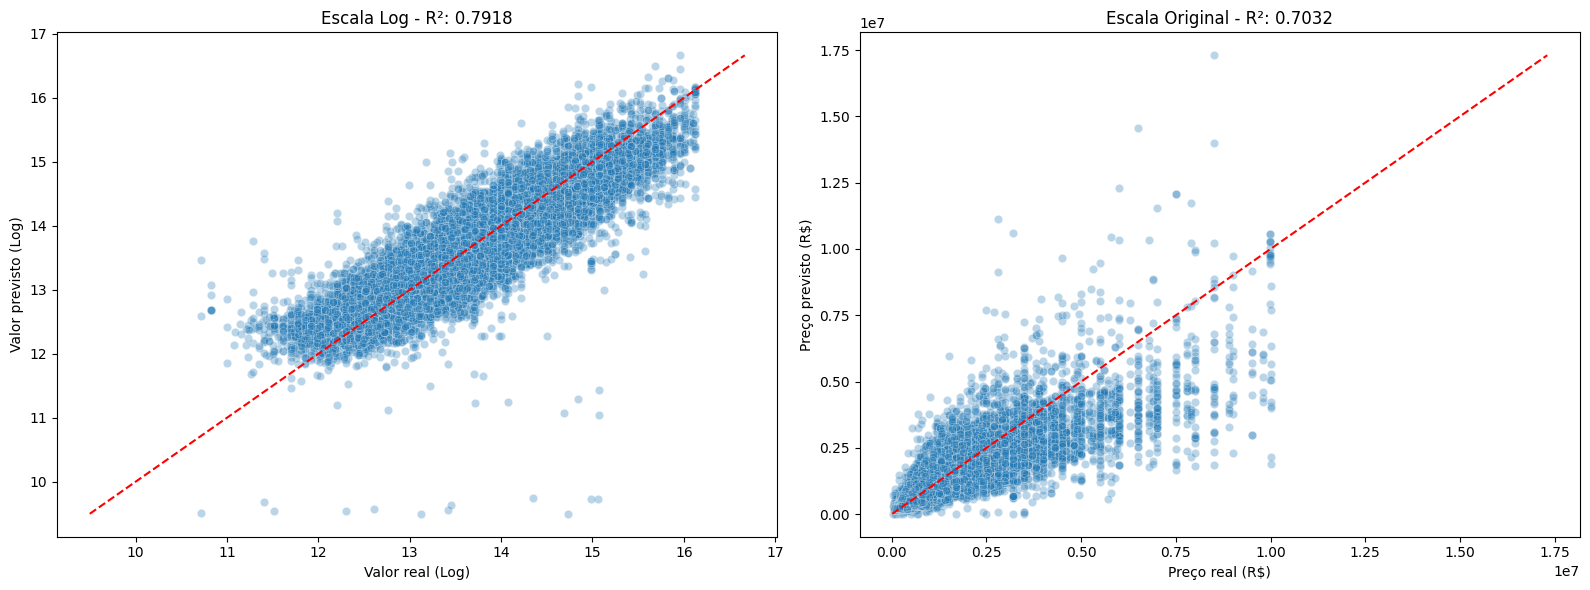

In [564]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Escala logarítmica
sns.scatterplot(
    x=y_teste,
    y=previsao_lr,
    alpha=0.3,
    ax=axes[0]
)

axes[0].set_title(f'Escala Log - R²: {r2_log:.4f}')
axes[0].set_xlabel('Valor real (Log)')
axes[0].set_ylabel('Valor previsto (Log)')

limites_log = [
    min(np.min(y_teste), np.min(previsao_lr)),
    max(np.max(y_teste), np.max(previsao_lr))
]
axes[0].plot(limites_log, limites_log, 'r--')

# Escala original
sns.scatterplot(
    x=y_real,
    y=y_previsto,
    alpha=0.3,
    ax=axes[1]
)

axes[1].set_title(f'Escala Original - R²: {r2_original:.4f}')
axes[1].set_xlabel('Preço real (R$)')
axes[1].set_ylabel('Preço previsto (R$)')

limites_original = [
    min(np.min(y_real), np.min(y_previsto)),
    max(np.max(y_real), np.max(y_previsto))
]
axes[1].plot(limites_original, limites_original, 'r--')

plt.tight_layout()
plt.show()


# Avaliação do Modelo de Regressão Linear

## 1. O que são métricas de regressão?

As métricas de regressão são utilizadas para avaliar a qualidade das previsões de um modelo.

No nosso projeto, o objetivo é prever o **preço de venda dos imóveis**. Para isso, comparamos:

- **Valor real (y):** preço verdadeiro do imóvel.
- **Valor previsto (ŷ):** preço estimado pelo modelo.
- **Erro (resíduo):** diferença entre o valor real e o previsto.

Quanto menores os erros, mais próximas as previsões estão dos valores reais.

---

## 2. MAE — Mean Absolute Error (Erro Absoluto Médio)

O MAE calcula a média dos erros absolutos das previsões, ignorando se o modelo errou para cima ou para baixo.

**Fórmula:**

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

**Exemplo:**

Suponha que o modelo tenha cometido erros de R$ 20 mil, R$ 30 mil e R$ 40 mil.

$$
MAE = \frac{20.000+30.000+40.000}{3}=30.000
$$

**Interpretação:** o modelo erra, em média, R$ 30 mil por imóvel.

- Quanto menor, melhor.
- Possui a mesma unidade da variável resposta.
- É menos sensível a erros extremos do que o MSE e o RMSE.

---

## 3. MSE — Mean Squared Error (Erro Quadrático Médio)

O MSE calcula a média dos erros elevados ao quadrado.

**Fórmula:**

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

**Por que elevar ao quadrado?**

Porque erros grandes recebem uma penalização proporcionalmente maior.

Por exemplo:

- Erro de 10 → quadrado = 100
- Erro de 100 → quadrado = 10.000

**Interpretação:**

- Quanto menor, melhor.
- Penaliza fortemente erros elevados.
- Sua unidade é o quadrado da unidade original, dificultando a interpretação direta em reais.

---

## 4. RMSE — Root Mean Squared Error (Raiz do Erro Quadrático Médio)

O RMSE é a raiz quadrada do MSE.

**Fórmula:**

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
$$

Ele também penaliza erros grandes, mas apresenta o resultado na mesma unidade da variável resposta.

**Exemplo:**

Se o RMSE for de R$ 80 mil, isso representa a magnitude dos erros considerando uma penalização maior para previsões muito distantes da realidade.

**Interpretação:**

- Quanto menor, melhor.
- É sensível a erros extremos.
- É útil para identificar modelos que cometem grandes erros em determinados imóveis.

**Atenção:** o RMSE não representa o erro absoluto médio. Essa interpretação pertence ao MAE.

---

## 5. R² — Coeficiente de Determinação

O R² mede quanto da variabilidade da variável resposta é explicada pelo modelo, em comparação com uma previsão que utiliza a média dos valores observados.

**Fórmula:**

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}{\sum_{i=1}^{n}(y_i-\bar{y})^2}
$$

Onde:

- **y:** valor real.
- **ŷ:** valor previsto.
- **ȳ:** média dos valores reais.

### Como interpretar?

| R² | Interpretação |
|---|---|
| 1,00 | Previsões perfeitas |
| 0,90 | Explica 90% da variância |
| 0,70 | Explica 70% da variância |
| 0,00 | Desempenho equivalente a prever sempre a média |
| Negativo | Desempenho pior que prever sempre a média |

**Importante:** um R² de 0,70 não significa que o modelo acerta 70% das previsões.

Também não significa necessariamente que o modelo seja bom ou ruim. A avaliação depende do problema, dos erros monetários e do objetivo do negócio.

---

## 6. Comparação das métricas

| Métrica | O que mede? | Melhor valor |
|---|---|---|
| MAE | Média dos erros absolutos | Menor |
| MSE | Média dos erros ao quadrado | Menor |
| RMSE | Magnitude dos erros com maior penalização dos erros grandes | Menor |
| R² | Variabilidade explicada pelo modelo | Maior, idealmente 1 |

### Quando utilizar cada uma?

**MAE:** quando queremos compreender o erro médio em uma unidade interpretável, como reais.

**MSE:** quando queremos penalizar fortemente os erros grandes, especialmente durante o treinamento e a comparação de modelos.

**RMSE:** quando erros grandes são particularmente importantes, mas queremos manter a unidade original.

**R²:** quando queremos avaliar quanto o modelo consegue explicar da variação dos preços, em relação à previsão pela média.

O ideal é analisar as métricas em conjunto.

---

## 7. Avaliação na escala logarítmica e na escala original

Neste projeto, utilizamos a transformação:

$$
y_{log}=\ln(1+y)
$$

Essa transformação pode ajudar a reduzir a assimetria da distribuição dos preços.

Para retornar à escala original, utilizamos:

$$
y=e^{y_{log}}-1
$$

Em Python:

- `np.log1p()` realiza a transformação logarítmica.
- `np.expm1()` realiza a transformação inversa.

### Escala logarítmica

As métricas são calculadas com os valores transformados.

Nessa escala, diferenças proporcionais entre preços recebem maior destaque do que na escala original.

### Escala original

As métricas são calculadas após reverter a transformação.

Essa avaliação permite interpretar MAE e RMSE diretamente em reais.

### Por que os resultados são diferentes?

Porque a transformação logarítmica é não linear.

Os erros não são preservados quando retornamos à escala monetária. Consequentemente, o R² também pode mudar.

**No nosso modelo:**

| Métrica | Escala logarítmica | Escala original |
|---|---|---|
| R² | 0,7918 | 0,7032 |

Na escala logarítmica, o modelo explica aproximadamente 79,18% da variância dos logaritmos dos preços.

Na escala original, explica aproximadamente 70,32% da variância dos preços em reais.

Esses valores avaliam o mesmo modelo sob perspectivas diferentes.

---

## 8. Conclusão

A avaliação de um modelo de regressão não deve depender de uma única métrica.

- O **MAE** ajuda a entender o erro médio.
- O **MSE** evidencia o impacto dos erros elevados.
- O **RMSE** destaca grandes erros em uma escala interpretável.
- O **R²** mostra o quanto da variação da variável resposta é explicada pelo modelo.

Para a previsão de preços imobiliários, as métricas em reais são especialmente importantes, pois permitem avaliar o impacto financeiro das diferenças entre preços reais e previstos.

Além das métricas, devemos analisar os gráficos de valores reais versus previstos e os resíduos, para identificar padrões de erro, possíveis vieses e limitações do modelo.


# Aula 3 - Árvore de Decisão para Regressão






## 3.1 - Árvore de Decisão Classificação versus Regressão

[slides]

[Biblioteca Sklearn - Desicion Tree](https://scikit-learn.org/stable/modules/tree.html#regression)

**Dica de leitura**: [Capítulo 6 - Mãos à obra: aprendizado de máquina com Scikit-Learn, Keras & TensorFlow: Conceitos, ferramentas e técnicas para a construção de sistemas inteligentes](https://www.amazon.com.br/M%C3%A3os-obra-aprendizado-Scikit-Learn-inteligentes/dp/8550815489/ref=sr_1_2?keywords=machine+learning&qid=1658181249&sprefix=machine%2Caps%2C469&sr=8-2&ufe=app_do%3Aamzn1.fos.6d798eae-cadf-45de-946a-f477d47705b9), [Para saber mais: como funciona a árvore de decisão? - Classificação](https://cursos.alura.com.br/course/machine-learning-classificacao-tras-panos/task/107966)



## 3.2 - Implementando o Modelo


**Gráfico de erro de predição**: Um gráfico de erros de predição mostra os alvos reais em relação aos valores previstos. Em um modelo perfeito, esses pontos estariam alinhados em 45 grau.


Para saber mais sobre outras visualizações:
[**Documentação YellowBrick**](https://www.scikit-yb.org/en/latest/)



## 3.3 - Métrica

# Aula 4 - Random Forest para Regressão


## 4.1 - Modelo Ensemble

[slides]

[Biblioteca Sklearn - Random Forest Regressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html#sklearn.ensemble.RandomForestRegressor)

**Dica de leitura**: [Artigo Científico - Random Forests](https://link.springer.com/article/10.1023/A:1010933404324), [Wikipédia: Random Forests](https://en.wikipedia.org/wiki/Random_forest#:~:text=Random%20forests%20or%20random%20decision,class%20selected%20by%20most%20trees.), [Capítulo 4 - Livro Introduction to Statistical and Machine Learning Methods for Data Science](https://www.amazon.com.br/dp/B09C2DVZHR/ref=dp-kindle-redirect?_encoding=UTF8&btkr=1), [Capítulo 7 - Mãos à obra: aprendizado de máquina com Scikit-Learn, Keras & TensorFlow: Conceitos, ferramentas e técnicas para a construção de sistemas inteligentes](https://www.amazon.com.br/M%C3%A3os-obra-aprendizado-Scikit-Learn-inteligentes/dp/8550815489/ref=sr_1_2?keywords=machine+learning&qid=1658181249&sprefix=machine%2Caps%2C469&sr=8-2&ufe=app_do%3Aamzn1.fos.6d798eae-cadf-45de-946a-f477d47705b9)

## 4.2 - Previsão

**Ponto de Atenção**
Os parâmetros são praticamente os mesmos entre o `DecisionTreeRegressor()` e o `RandomForestRegressor()`, com exceção de:

* `n_estimators`: quantidade de árvores na floresta
* `bootstrap`: define se será utilizado o método estatístico de amostragem *bootstrap*
* `oob_score`: define se será utilizado o método de amostragem *out-of-bag* para mensurar os erros da predição
* `n_jobs`: número de *jobs* rodando paralelamente (computação paralela - processadores)
* `warm_start`: faz a adequação de uma nova floresta ou usa uma floresta existente.
* `max_samples`: para o caso do `bootstrap` ser `True`, define o número de amostras a serem extraídas de X para treinar cada árvore base.

**Gráfico de erro de predição**

## 4.3 - Métrica de desempenho

# Aula 5 - Técnicas de Otimização


## 5.1 - Ferramentas de Otimização

* Por que otimizar?

* Quais ferramentas temos?

[Melhorando os hiperparâmetros - Documentação Sklearn](https://scikit-learn.org/stable/modules/grid_search.html#tuning-the-hyper-parameters-of-an-estimator)

### 1. Cross Validation (Validação Cruzada)

* [Documentação Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)

* **Cross Validation** é uma técnica muito utilizada para avaliação de desempenho de modelos e consequente verificação de tendências no aprendizado de máquina. Ele consiste em particionar os dados em subconjuntos (partes), onde um subconjunto é utilizado para treino e outro subconjunto é utilizado para teste e avaliação do desempenho do modelo.

* Os dados particionados são os de treino (70% dos dados originais)!

* **K-fold**: conjunto de treino é dividido de forma aleatória em K subconjuntos de aproximadamente mesmo tamanho, depois são realizados K iterações, onde K-1 subconjuntos são para treino e 1 para validação.

* O desempenho calculado pela validação cruzada k-fold é a média de todos os valores calculados em cada iteração.


### 2. Randomized Parameter Optimization (Otimização Aleatória de Parâmetros)

* [Documentação Randomized Search](https://scikit-learn.org/stable/modules/grid_search.html#randomized-parameter-optimization)

* [Artigo Científico sobre Random Search](https://www.jmlr.org/papers/volume13/bergstra12a/bergstra12a.pdf)

* "Define um espaço de busca como um domínio limitado de valores de hiperparâmetros e pontos de amostra aleatórios nesse domínio."

* Imagem no artigo sobre funcionamento desta busca



## 5.2 - Otimizando a árvore de decisão

### Cross validation


### Random Search Validação

### Random Search Teste

## 5.3 - Otimizando a Random Forest

### Cross validation

### Random Search Validação

Definindo os parâmetros

### Random Search Teste

## 5.4 - Escolhendo o melhor modelo